In [1]:
# Install required libraries
# %pip install -U datasets transformers evaluate sentence-transformers huggingface_hub scikit-learn pandas matplotlib

# Hugging Face NLP Project — Important Libraries & Functions

## 1. Datasets — Data Loading & Processing

**Important Imports:**
```python
from datasets import load_dataset, Dataset, DatasetDict
```

| Function / Class | Purpose |
|---|---|
| `load_dataset()` | Load datasets from Hugging Face Hub or files |
| `Dataset.from_dict()` | Create a dataset from a dictionary |
| `Dataset.from_pandas()` | Create a dataset from a DataFrame |
| `DatasetDict` | Store multiple dataset splits |
| `dataset.select()` | Select specific rows |
| `dataset.shuffle()` | Randomly shuffle rows |
| `dataset.filter()` | Filter data using conditions |
| `dataset.map()` | Apply a function to dataset rows |
| `dataset.train_test_split()` | Create training and test splits |
| `dataset.to_pandas()` | Convert dataset to DataFrame |

## 2. Transformers — Pretrained NLP Models

**Important Imports:**
```python
from transformers import pipeline, AutoTokenizer, AutoModel
from transformers import AutoConfig, AutoModelForSequenceClassification
```

| Function / Class | Purpose |
|---|---|
| `pipeline()` | Perform NLP tasks directly |
| `AutoTokenizer.from_pretrained()` | Load a pretrained tokenizer |
| `AutoModel.from_pretrained()` | Load a base pretrained model |
| `AutoConfig.from_pretrained()` | Load model configuration |
| `AutoModelForSequenceClassification` | Load model for text classification |
| `tokenizer()` | Convert text into model inputs |
| `tokenizer.decode()` | Convert token IDs into text |
| `model.eval()` | Set model to evaluation mode |

## 3. Evaluate — Model Performance

**Important Import:**
```python
import evaluate
```

| Function | Purpose |
|---|---|
| `evaluate.load("accuracy")` | Load accuracy metric |
| `evaluate.load("precision")` | Load precision metric |
| `evaluate.load("recall")` | Load recall metric |
| `evaluate.load("f1")` | Load F1 metric |
| `metric.compute()` | Calculate the selected metric |
| `evaluate.combine()` | Combine multiple metrics |

## 4. Sentence Transformers — Text Embeddings

**Important Imports:**
```python
from sentence_transformers import SentenceTransformer, util
```

| Function / Class | Purpose |
|---|---|
| `SentenceTransformer()` | Load a sentence embedding model |
| `model.encode()` | Convert text into embeddings |
| `util.cos_sim()` | Calculate cosine similarity |
| `util.semantic_search()` | Search for similar text |
| `model.similarity()` | Compare sentence embeddings |

## 5. Hugging Face Hub — Model & Dataset Sharing

**Important Imports:**
```python
from huggingface_hub import login, logout, HfApi
from huggingface_hub import hf_hub_download, snapshot_download
from huggingface_hub import InferenceClient
```

| Function / Class | Purpose |
|---|---|
| `login()` | Log in to Hugging Face |
| `logout()` | Log out of Hugging Face |
| `HfApi()` | Access Hub management APIs |
| `api.create_repo()` | Create a repository |
| `api.upload_file()` | Upload a single file |
| `api.upload_folder()` | Upload a folder |
| `hf_hub_download()` | Download a single file |
| `snapshot_download()` | Download repository files |
| `InferenceClient()` | Run models through inference APIs |

## 6. Scikit-learn — Machine Learning Evaluation

**Important Imports:**
```python
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics.pairwise import cosine_similarity
```

| Function | Purpose |
|---|---|
| `accuracy_score()` | Calculate prediction accuracy |
| `precision_score()` | Calculate precision |
| `recall_score()` | Calculate recall |
| `f1_score()` | Calculate F1 score |
| `classification_report()` | Display classification metrics |
| `confusion_matrix()` | Show correct and incorrect predictions |
| `cosine_similarity()` | Compare numerical vectors |

## 7. Pandas — Data Analysis

**Important Import:**
```python
import pandas as pd
```

| Function | Purpose |
|---|---|
| `pd.DataFrame()` | Create a DataFrame |
| `pd.read_csv()` | Read a CSV file |
| `pd.read_json()` | Read a JSON file |
| `df.head()` | Display first rows |
| `df.info()` | Display dataset information |
| `df.describe()` | Display statistical summary |
| `df.isnull().sum()` | Count missing values |
| `df.value_counts()` | Count unique values |
| `df.dropna()` | Remove missing values |
| `df.to_csv()` | Save results to CSV |

## 8. Matplotlib — Data Visualization

**Important Import:**
```python
import matplotlib.pyplot as plt
```

| Function | Purpose |
|---|---|
| `plt.figure()` | Create a figure |
| `plt.plot()` | Draw a line graph |
| `plt.bar()` | Draw a bar chart |
| `plt.hist()` | Draw a histogram |
| `plt.pie()` | Draw a pie chart |
| `plt.scatter()` | Draw a scatter plot |
| `plt.xlabel()` | Set X-axis label |
| `plt.ylabel()` | Set Y-axis label |
| `plt.title()` | Set chart title |
| `plt.legend()` | Display chart legend |
| `plt.savefig()` | Save the figure |
| `plt.show()` | Display the figure |

---

## Quick Reminder — Project Workflow

1. **datasets** → Load and process movie reviews.
2. **pandas** → Explore and organize the data.
3. **matplotlib** → Visualize sentiment distribution.
4. **transformers** → Tokenize reviews and predict sentiment.
5. **evaluate** → Measure classification performance.
6. **scikit-learn** → Generate detailed evaluation metrics.
7. **sentence-transformers** → Find semantically similar reviews.
8. **huggingface_hub** → Download and publish project assets.

**Note:** Imports load modules, classes, or functions. Methods such as `dataset.map()` and `df.head()` are called on objects after those objects have been created.

In [2]:
# Import Python utilities
import json
import re
from pathlib import Path

# Import data libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Import Hugging Face libraries
import torch
import evaluate
from datasets import load_dataset
from transformers import AutoConfig, AutoTokenizer, AutoModelForSequenceClassification, pipeline
from sentence_transformers import SentenceTransformer

# Import evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Create output folder
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Setup complete")

W1021 01:03:24.367000 25172 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Setup complete


In [3]:
# Set random seed
SEED = 42

# Set dataset sample sizes
EVAL_SAMPLES = 100
SEARCH_SAMPLES = 60

# Select pretrained models
CLASSIFIER_MODEL = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"
EMBEDDING_MODEL = "sentence-transformers/all-MiniLM-L6-v2"

# Select GPU or CPU
DEVICE = 0 if torch.cuda.is_available() else -1

# Display configuration
print("Evaluation samples:", EVAL_SAMPLES)
print("Search samples:", SEARCH_SAMPLES)
print("Running on:", "GPU" if DEVICE == 0 else "CPU")

Evaluation samples: 100
Search samples: 60
Running on: GPU


In [4]:
# Load IMDb test dataset
full_test = load_dataset("stanfordnlp/imdb", split="test")

# Shuffle dataset
shuffled_test = full_test.shuffle(seed=SEED)

# Select working samples
sampled_test = shuffled_test.select(range(EVAL_SAMPLES + SEARCH_SAMPLES))

# Create separate subsets
eval_ds = sampled_test.select(range(EVAL_SAMPLES))
search_ds = sampled_test.select(range(EVAL_SAMPLES, EVAL_SAMPLES + SEARCH_SAMPLES))

# Display dataset information
print("Full test size:", len(full_test))
print("Evaluation size:", len(eval_ds))
print("Search size:", len(search_ds))
print("Columns:", eval_ds.column_names)
print("Features:", eval_ds.features)

Full test size: 25000
Evaluation size: 100
Search size: 60
Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}


In [5]:
# Display dataset columns
print("Columns:", eval_ds.column_names)

# Display dataset features
print("Features:", eval_ds.features)

# Display first review
print("Review:", eval_ds[0]["text"][:300])

# Display review label
print("Label:", eval_ds[0]["label"])

Columns: ['text', 'label']
Features: {'text': Value('string'), 'label': ClassLabel(names=['neg', 'pos'])}
Review: <br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I sta
Label: 1


In [6]:
# Convert dataset to DataFrame
df = eval_ds.to_pandas()

# Convert labels to sentiment names
df["sentiment"] = df["label"].map({0: "Negative", 1: "Positive"})

# Display first five rows
print(df.head())

# Display sentiment counts
print(df["sentiment"].value_counts())

                                                text  label sentiment
0  <br /><br />When I unsuspectedly rented A Thou...      1  Positive
1  This is the latest entry in the long series of...      1  Positive
2  This movie was so frustrating. Everything seem...      0  Negative
3  I was truly and wonderfully surprised at "O' B...      1  Positive
4  This movie spends most of its time preaching t...      0  Negative
sentiment
Negative    53
Positive    47
Name: count, dtype: int64


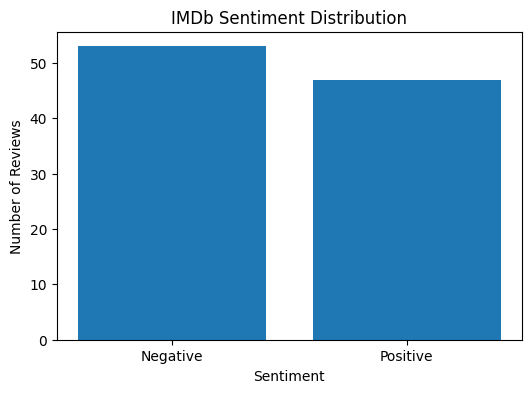

In [7]:
# Count reviews by sentiment
counts = df["sentiment"].value_counts()

# Create bar chart
plt.figure(figsize=(6, 4))

# Plot sentiment counts
plt.bar(counts.index, counts.values)

# Add chart labels
plt.title("IMDb Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# Display chart
plt.show()

count    100.000000
mean     192.180000
std      110.322519
min       48.000000
25%      125.750000
50%      157.000000
75%      231.500000
max      744.000000
Name: word_count, dtype: float64


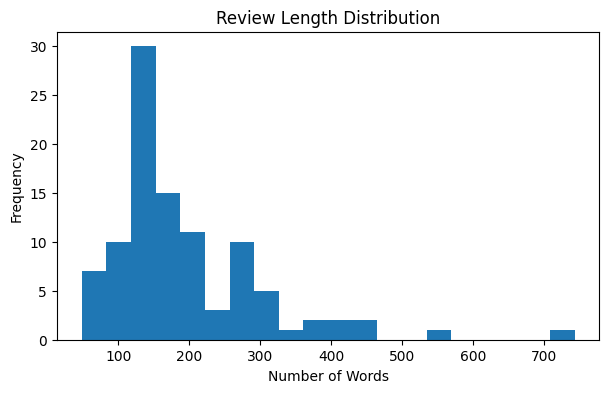

In [8]:
# Calculate review word counts
df["word_count"] = df["text"].str.split().str.len()

# Display summary statistics
print(df["word_count"].describe())

# Plot review lengths
plt.figure(figsize=(7, 4))
plt.hist(df["word_count"], bins=20)

# Add chart labels
plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

# Display chart
plt.show()

In [9]:
# Check missing reviews
print("Missing Reviews:", sum(text is None for text in eval_ds["text"]))

# Check empty reviews
print("Empty Reviews:", sum(not text or not text.strip() for text in eval_ds["text"]))

# Display first review
print(eval_ds[0]["text"][:300])

Missing Reviews: 0
Empty Reviews: 0
<br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I sta


In [11]:
# Import text cleaning tools
from html import unescape

# Define review cleaning function
def clean_review(example):

    # Convert HTML entities to normal text
    text = unescape(example["text"] or "")

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Return cleaned text
    return {"clean_text": text}

In [12]:
# Clean evaluation reviews
eval_clean_ds = eval_ds.map(clean_review)

# Clean search reviews
search_clean_ds = search_ds.map(clean_review)

# Remove empty cleaned reviews
eval_clean_ds = eval_clean_ds.filter(lambda x: bool(x["clean_text"]))
search_clean_ds = search_clean_ds.filter(lambda x: bool(x["clean_text"]))

# Display dataset sizes
print("Evaluation Reviews:", len(eval_clean_ds))
print("Search Reviews:", len(search_clean_ds))

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Map:   0%|          | 0/60 [00:00<?, ? examples/s]

Filter:   0%|          | 0/100 [00:00<?, ? examples/s]

Filter:   0%|          | 0/60 [00:00<?, ? examples/s]

Evaluation Reviews: 100
Search Reviews: 60


In [13]:
# Display original review
print("Original Review:")
print(eval_clean_ds[0]["text"][:300])

# Display cleaned review
print("\nCleaned Review:")
print(eval_clean_ds[0]["clean_text"][:300])

# Display sentiment label
print("\nLabel:", eval_clean_ds[0]["label"])

Original Review:
<br /><br />When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong?<br /><br />Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I sta

Cleaned Review:
When I unsuspectedly rented A Thousand Acres, I thought I was in for an entertaining King Lear story and of course Michelle Pfeiffer was in it, so what could go wrong? Very quickly, however, I realized that this story was about A Thousand Other Things besides just Acres. I started crying and couldn'

Label: 1


In [14]:
# Save evaluation dataset
eval_clean_ds.to_csv(OUTPUT_DIR / "imdb_eval_clean.csv")

# Save search dataset
search_clean_ds.to_csv(OUTPUT_DIR / "imdb_search_clean.csv")

# Confirm saved files
print("Cleaned datasets saved successfully!")

Creating CSV from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Creating CSV from Arrow format:   0%|          | 0/1 [00:00<?, ?ba/s]

Cleaned datasets saved successfully!


In [15]:
# Load pretrained tokenizer
tokenizer = AutoTokenizer.from_pretrained(CLASSIFIER_MODEL)

# Display tokenizer information
print("Tokenizer:", type(tokenizer).__name__)
print("Vocabulary Size:", tokenizer.vocab_size)
print("Max Length:", tokenizer.model_max_length)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

c:\Users\Muhammad Irfan\miniconda3\envs\genai\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Muhammad Irfan\.cache\huggingface\hub\models--distilbert--distilbert-base-uncased-finetuned-sst-2-english. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

Tokenizer: BertTokenizer
Vocabulary Size: 30522
Max Length: 512


In [17]:
# Select first five reviews
reviews = eval_clean_ds["clean_text"][:5]

# Tokenize reviews in a batch
batch = tokenizer(
    reviews,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

# Display tensor shapes
print("Input IDs:", batch["input_ids"].shape)
print("Attention Mask:", batch["attention_mask"].shape)

Input IDs: torch.Size([5, 256])
Attention Mask: torch.Size([5, 256])


In [18]:
# Load pretrained sentiment model
model = AutoModelForSequenceClassification.from_pretrained(CLASSIFIER_MODEL)

# Select available device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Move model to device
model = model.to(device)

# Enable evaluation mode
model.eval()

# Display model information
print("Model:", model.config.model_type)
print("Labels:", model.config.id2label)
print("Device:", device)

c:\Users\Muhammad Irfan\miniconda3\envs\genai\lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Muhammad Irfan\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model: distilbert
Labels: {0: 'NEGATIVE', 1: 'POSITIVE'}
Device: cuda


In [21]:
# Select a cleaned review
review = eval_clean_ds[0]["clean_text"]

# Tokenize review
inputs = tokenizer(review, return_tensors="pt", truncation=True, max_length=256)

# Move inputs to device
inputs = {key: value.to(device) for key, value in inputs.items()}

# Generate prediction
with torch.no_grad():
    outputs = model(**inputs)

# Convert logits into probabilities
probabilities = torch.softmax(outputs.logits, dim=-1)

# Get predicted class
predicted_id = probabilities.argmax(dim=-1).item()

# Display prediction
print("Prediction:", model.config.id2label[predicted_id])
print("Confidence:", round(probabilities[0][predicted_id].item(), 4))
print("Actual Label:", eval_clean_ds[0]["label"])

Prediction: POSITIVE
Confidence: 0.9994
Actual Label: 1


In [24]:
# Create sentiment analysis pipeline
sentiment_pipe = pipeline(
    "text-classification",
    model=model,
    tokenizer=tokenizer,
    device=DEVICE
)

# Test pipeline
result = sentiment_pipe("This movie was amazing!")

print(result)

[{'label': 'POSITIVE', 'score': 0.9998800754547119}]


In [25]:
# Get cleaned reviews
reviews = list(eval_clean_ds["clean_text"])

# Predict sentiment for all reviews
predictions = sentiment_pipe(
    reviews,
    truncation=True,
    max_length=256,
    batch_size=8
)

# Display first five predictions
print(predictions[:5])

[{'label': 'POSITIVE', 'score': 0.999427318572998}, {'label': 'POSITIVE', 'score': 0.9969831109046936}, {'label': 'NEGATIVE', 'score': 0.9972442388534546}, {'label': 'NEGATIVE', 'score': 0.6492092609405518}, {'label': 'NEGATIVE', 'score': 0.9985034465789795}]


In [26]:
# Define sentiment labels
label_map = {"NEGATIVE": 0, "POSITIVE": 1}

# Get actual labels
y_true = list(eval_clean_ds["label"])

# Convert predictions into numeric labels
y_pred = [label_map[p["label"]] for p in predictions]

# Get prediction confidence scores
confidence = [p["score"] for p in predictions]

# Display first five results
for i in range(5):
    print("Actual:", y_true[i], "Predicted:", y_pred[i])

Actual: 1 Predicted: 1
Actual: 1 Predicted: 1
Actual: 0 Predicted: 0
Actual: 1 Predicted: 0
Actual: 0 Predicted: 0


In [27]:
# Load accuracy metric
accuracy_metric = evaluate.load("accuracy")

# Calculate accuracy
accuracy = accuracy_metric.compute(
    predictions=y_pred,
    references=y_true
)

# Calculate classification metrics
precision = precision_score(y_true, y_pred, zero_division=0)
recall = recall_score(y_true, y_pred, zero_division=0)
f1 = f1_score(y_true, y_pred, zero_division=0)

# Display results
print("Accuracy:", round(accuracy["accuracy"], 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.88
Precision: 0.9268
Recall: 0.8085
F1 Score: 0.8636


              precision    recall  f1-score   support

    Negative       0.85      0.94      0.89        53
    Positive       0.93      0.81      0.86        47

    accuracy                           0.88       100
   macro avg       0.89      0.88      0.88       100
weighted avg       0.88      0.88      0.88       100



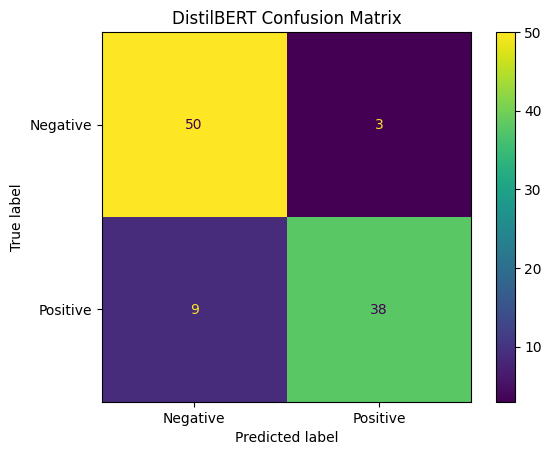

In [29]:
# Display classification report
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=[0, 1],
    display_labels=["Negative", "Positive"]
)

# Display graph
plt.title("DistilBERT Confusion Matrix")
plt.show()

In [30]:
# Create results DataFrame
results_df = pd.DataFrame({
    "review": reviews,
    "actual": y_true,
    "predicted": y_pred,
    "confidence": confidence
})

# Check correct predictions
results_df["correct"] = results_df["actual"] == results_df["predicted"]

# Save predictions
results_df.to_csv(OUTPUT_DIR / "sentiment_predictions.csv", index=False)

# Display results
print(results_df.head())
print("Results saved successfully!")

                                              review  actual  predicted  \
0  When I unsuspectedly rented A Thousand Acres, ...       1          1   
1  This is the latest entry in the long series of...       1          1   
2  This movie was so frustrating. Everything seem...       0          0   
3  I was truly and wonderfully surprised at "O' B...       1          0   
4  This movie spends most of its time preaching t...       0          0   

   confidence  correct  
0    0.999427     True  
1    0.996983     True  
2    0.997244     True  
3    0.649209    False  
4    0.998503     True  
Results saved successfully!
